In [ ]:
import sqlite3
import pandas as pd

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Airline_Delay_Cause.csv to Airline_Delay_Cause.csv


In [ ]:
conn = sqlite3.connect("Airline_Delay_Cause.db")
cursor = conn.cursor()

In [ ]:

cursor.execute("""
CREATE TABLE IF NOT EXISTS dim_airline (
    carrier TEXT PRIMARY KEY,
    carrier_name TEXT
);
""")
cursor.execute("""
CREATE TABLE IF NOT EXISTS dim_airport (
    airport_id INTEGER PRIMARY KEY AUTOINCREMENT,
    airport_code TEXT UNIQUE,
    airport_name TEXT
);
""")
cursor.execute("""
CREATE TABLE IF NOT EXISTS dim_time (
    time_id INTEGER PRIMARY KEY AUTOINCREMENT,
    year INTEGER,
    month INTEGER,
    UNIQUE(year, month)
);

""")
cursor.execute("""
CREATE TABLE IF NOT EXISTS dim_delay_type (
    delay_type_id INTEGER PRIMARY KEY AUTOINCREMENT,
    delay_type TEXT UNIQUE
);
""")
cursor.execute("""
CREATE TABLE IF NOT EXISTS fact_flight_delay (
    fact_id INTEGER PRIMARY KEY AUTOINCREMENT,

    airline_id INTEGER,
    airport_id INTEGER,
    time_id INTEGER,
    delay_type_id INTEGER,

    arr_flights REAL,
    arr_del15 REAL,
    arr_cancelled REAL,
    arr_diverted REAL,

    arr_delay REAL,
    delay_value REAL,

    FOREIGN KEY (airline_id) REFERENCES dim_airline(airline_id),
    FOREIGN KEY (airport_id) REFERENCES dim_airport(airport_id),
    FOREIGN KEY (time_id) REFERENCES dim_time(time_id),
    FOREIGN KEY (delay_type_id) REFERENCES dim_delay_type(delay_type_id)
);
""")




conn.commit()

print("Star Schema Created Successfully ⭐")


Star Schema Created Successfully ⭐


In [ ]:
tables = cursor.execute("""
SELECT name FROM sqlite_master WHERE type='table';
""").fetchall()

print("\nTables in Data Warehouse:")
for t in tables:
    print(t[0])



Tables in Data Warehouse:
dim_airline
dim_airport
sqlite_sequence
dim_time
dim_delay_type
fact_flight_delay


In [ ]:

conn.close()

print("\nDone 🎯 Data Warehouse Ready!")


Done 🎯 Data Warehouse Ready!


In [ ]:
###Sara's Part
import pandas as pd

dfb = pd.read_csv("Airline_Delay_Cause.csv")

df = pd.read_csv("Airline_Delay_Cause.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Airline_Delay_Cause.csv'

In [ ]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318017 entries, 0 to 318016
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 318017 non-null  int64  
 1   month                318017 non-null  int64  
 2   carrier              318013 non-null  object 
 3   carrier_name         318013 non-null  object 
 4   airport              318014 non-null  object 
 5   airport_name         318017 non-null  object 
 6   arr_flights          317524 non-null  float64
 7   arr_del15            317285 non-null  float64
 8   carrier_ct           317525 non-null  float64
 9   weather_ct           317523 non-null  float64
 10  nas_ct               317529 non-null  float64
 11  security_ct          317529 non-null  float64
 12  late_aircraft_ct     317529 non-null  float64
 13  arr_cancelled        317529 non-null  float64
 14  arr_diverted         317527 non-null  float64
 15  arr_delay        

,0
year,0
month,0
carrier,4
carrier_name,4
airport,3
airport_name,0
arr_flights,493
arr_del15,732
carrier_ct,492
weather_ct,494


In [ ]:
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Missing values:
 year                     0
month                    0
carrier                  4
carrier_name             4
airport                  3
airport_name             0
arr_flights            493
arr_del15              732
carrier_ct             492
weather_ct             494
nas_ct                 488
security_ct            488
late_aircraft_ct       488
arr_cancelled          488
arr_diverted           490
arr_delay              494
carrier_delay          492
weather_delay          488
nas_delay              488
security_delay         490
late_aircraft_delay    488
dtype: int64
Duplicates: 0


In [ ]:
df = df.drop_duplicates()

In [ ]:
df.fillna(0, inplace=True)

In [ ]:
df = df[df['arr_flights'] > 0]
df = df[df['arr_del15'] >= 0]

In [ ]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [ ]:
print("After cleaning:")
df.info()
df.isnull().sum()

In [ ]:
print("Shape before cleaning:", dfb.shape)
# cleaning
print("Shape after cleaning:", df.shape)

In [ ]:
df.to_csv("cleaned_airline_data.csv", index=False)

In [ ]:
files.download("cleaned_airline_data.csv")

In [ ]:
df = pd.read_csv("cleaned_airline_data.csv")

In [ ]:
df['delay_ratio'] = df['arr_del15'] / df['arr_flights']

In [ ]:
df['cancellation_rate'] = df['arr_cancelled'] / df['arr_flights']

In [ ]:
df['diversion_rate'] = df['arr_diverted'] / df['arr_flights']

In [ ]:
df['avg_delay_per_flight'] = df['arr_delay'] / df['arr_del15'].replace(0, 1)

In [ ]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['season'] = df['month'].apply(get_season)

In [ ]:
df['is_delayed'] = (df['delay_ratio'] > 0.2).astype(int)

In [ ]:
print("New features :")
print(df[['delay_ratio', 'cancellation_rate', 'diversion_rate',
          'avg_delay_per_flight', 'season', 'is_delayed']].head())

print("\nShape after transformation:", df.shape)

In [ ]:
df.to_csv("transformed_airline_data.csv", index=False)
files.download("transformed_airline_data.csv")

# New Section

LANA PART


In [ ]:
import kagglehub
path = kagglehub.dataset_download("abdelazizel7or/airline-delay-cause")

100%|██████████| 10.5M/10.5M [00:00<00:00, 132MB/s]

Extracting files...


In [ ]:
import pandas as pd
df = pd.read_csv(path+"/Airline_Delay_Cause.csv")
df.head()

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",136.0,7.0,5.95,0.00,...,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",91.0,16.0,7.38,0.00,...,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,9E,Endeavor Air Inc.,ACK,"Nantucket, MA: Nantucket Memorial",19.0,2.0,0.13,0.00,...,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,14.0,7.26,0.76,...,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",181.0,19.0,13.84,0.00,...,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0


Model                | Train R2   | Test R2    | MAE       
------------------------------------------------------------
Linear Regression    | 0.842      | 0.856      | 25.66     
Decision Tree        | 1.000      | 0.866      | 22.93     
Random Forest        | 0.990      | 0.932      | 16.66     


/tmp/ipykernel_552/4173761239.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')


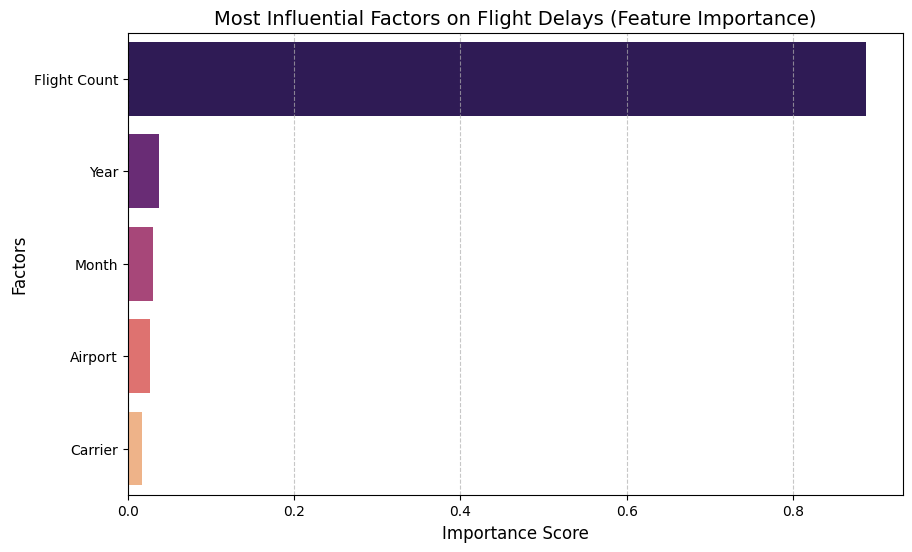

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error


columns_to_use = ['year', 'month', 'carrier', 'airport', 'arr_flights', 'arr_del15']

df_mining = df[columns_to_use].dropna().copy()


le_carrier = LabelEncoder()
le_airport = LabelEncoder()

df_mining['carrier_idx'] = le_carrier.fit_transform(df_mining['carrier'])
df_mining['airport_idx'] = le_airport.fit_transform(df_mining['airport'])


X = df_mining[['year', 'month', 'carrier_idx', 'airport_idx', 'arr_flights']]
y = df_mining['arr_del15']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

print(f"{'Model':<20} | {'Train R2':<10} | {'Test R2':<10} | {'MAE':<10}")
print("-" * 60)

for name, model in models.items():
    # تدريب الموديل
    model.fit(X_train, y_train)

    # التوقع
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # حساب المقاييس
    tr_r2 = r2_score(y_train, train_pred)
    te_r2 = r2_score(y_test, test_pred)
    mae = mean_absolute_error(y_test, test_pred)

    print(f"{name:<20} | {tr_r2:<10.3f} | {te_r2:<10.3f} | {mae:<10.2f}")


#best_model = models["Random Forest"]
#importances = best_model.feature_importances_
#features_names = ['year', 'month', 'carrier', 'airport', 'flights_count']

#print("\n" + "="*30)
#print("most influential factors on delay ")
#for name, imp in zip(features_names, importances):
   # print(f"{name:<15}: {imp:.4f}")
import seaborn as sns
import matplotlib.pyplot as plt


features_names = ['Year', 'Month', 'Carrier', 'Airport', 'Flight Count']
best_model = models["Random Forest"]
importances = best_model.feature_importances_


feature_imp_df = pd.DataFrame({'Feature': features_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# 3 Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')


plt.title('Most Influential Factors on Flight Delays (Feature Importance)', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Factors', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()


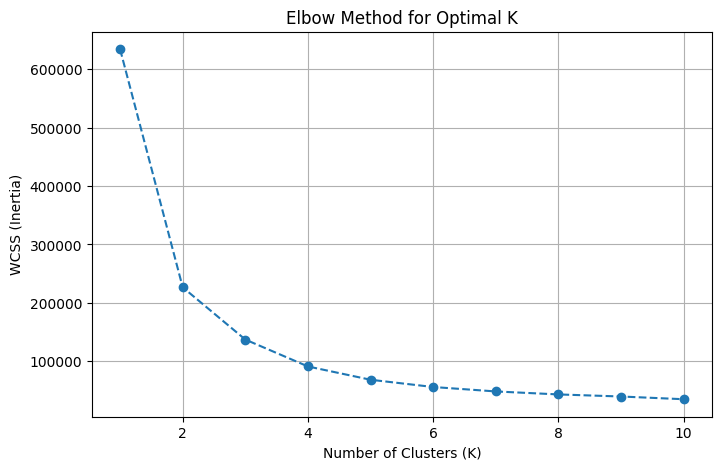


K-MEANS CLUSTERING RESULTS
Status: Successfully grouped data into 3 clusters.

Cluster Statistics (Mean Values):
         arr_flights    arr_del15
Cluster                          
0        3648.458902   654.464793
1        9352.655276  1931.280576
2         212.664328    41.315614


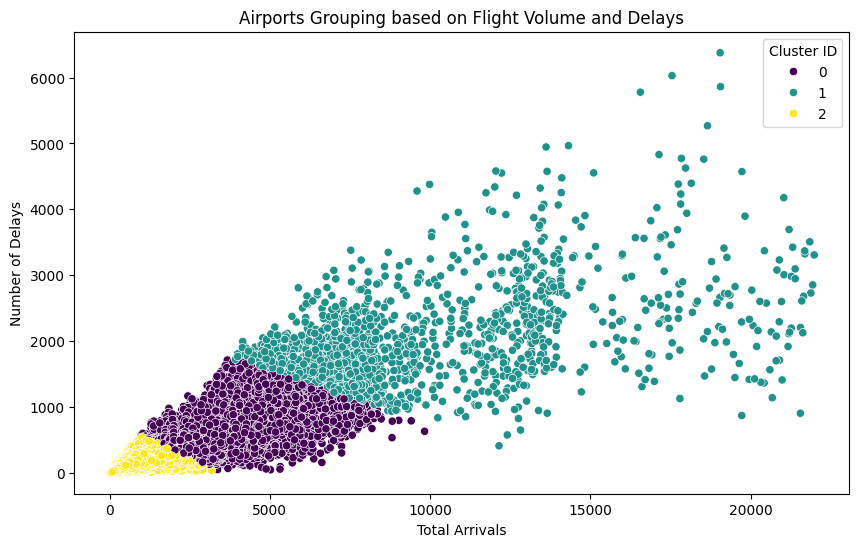


Process Completed: Clusters have been identified and visualized.


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Prepare Data for Clustering (Focusing on Flights and Delays)
# Using 'arr_flights' and 'arr_del15' to group similar airport behaviors
cluster_features = ['arr_flights', 'arr_del15']
df_clustering = df[cluster_features].dropna().copy()

# 2. Feature Scaling (Essential for K-Means)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_clustering)

# 3. Finding Optimal K using the Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

# Visualizing the Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

# 4. Applying K-Means Clustering
# Let's assume K=3 (Low, Medium, and High Delay Risk Groups)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)
df_clustering['Cluster'] = kmeans.fit_predict(scaled_data)

# 5. Displaying Results
print("\n" + "="*50)
print("K-MEANS CLUSTERING RESULTS")
print("="*50)
print(f"Status: Successfully grouped data into {optimal_k} clusters.")
print("\nCluster Statistics (Mean Values):")
print(df_clustering.groupby('Cluster').mean())

# 6. Visualizing the Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clustering, x='arr_flights', y='arr_del15', hue='Cluster', palette='viridis')
plt.title('Airports Grouping based on Flight Volume and Delays')
plt.xlabel('Total Arrivals')
plt.ylabel('Number of Delays')
plt.legend(title='Cluster ID')
plt.show()

print("\nProcess Completed: Clusters have been identified and visualized.")

#STREAMLIT
